# TOFFEE Flare Energies

Getting from a detected flare to a physical energy is a short procedure once you have an equivalent duration (ED): look at what ED actually measures, get it two ways (straight from `detect_flares()`, and from a fitted model), then hand it to `flare_energy_calc()` along with the star's luminosity.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import toffee

## 1. Reload the light curve and detect flares

Same target as notebooks 1-4.

In [2]:
################ TUTORIAL TARGET ################
#change these two values to try a different star/sector
TIC_ID = 84336253
SECTOR = 43

import lightkurve as lk

search_result = lk.search_lightcurve(f'TIC {TIC_ID}', mission = 'TESS', author = 'SPOC',
                                     exptime = 120, sector = SECTOR)
lc = search_result.download()

time = np.asarray(lc.time.value, dtype = float)
flux = np.asarray(lc.flux.value, dtype = float)
flux_err = np.asarray(lc.flux_err.value, dtype = float)

finite = np.isfinite(time) & np.isfinite(flux) & np.isfinite(flux_err)
time, flux, flux_err = time[finite], flux[finite], flux_err[finite]

orbit_time, lc_quad, lc_wotan, periodic = toffee.flatten(time, flux, flux_err, short_window = 0.25)
flat_flux, flat_flux_err = lc_wotan[0], lc_wotan[1]
quality = np.zeros(len(orbit_time))

flares = toffee.detect_flares(orbit_time, flat_flux, flat_flux_err, quality)
flares

,T_peak,T_start,T_end,Amplitude,ED,Primary_or_Secondary,Num_Points,Num_Abv_Threshold,Amp_Sigma
0,2475.422539,2475.414205,2475.439207,0.296309,333.924647,primary,18,15,10.766277
1,2493.110102,2493.105935,2493.193441,3.026989,5359.732806,primary,64,57,109.984543
2,2493.115658,2493.115658,2493.119825,0.424544,86.751489,secondary,4,4,14.835562


## 2. What equivalent duration actually measures

A flare's **equivalent duration (ED)** is the area between the flux curve and the quiescent baseline (`flux = 1`), with time as the x-axis:

$$\mathrm{ED} = \int (\,\mathrm{flux} - 1\,) \, dt$$

Since `flux` is a ratio (flare flux over quiescent flux) and `t` has units of time, ED itself comes out in units of **time**: seconds, in TOFFEE's convention. That's not an accident: ED is literally *"how many seconds would the star need to shine at its normal, quiescent brightness to radiate as much energy as the flare just did."* A bigger, longer flare has a bigger ED; multiplying that by the star's actual quiescent luminosity (section 4) converts it directly into an energy.

TOFFEE computes this integral with the trapezoidal rule: connect consecutive data points with a straight line, and the area under each pair of points is a trapezoid. `flares`' own rows are all either very small or complicated by an overlapping secondary (section 4 uses that complication on purpose), so this example borrows one clean, isolated, textbook-shaped flare from TIC 114029415 (the same star used for the `fit_multiple_secs` example in notebook 3, just a different, simpler flare from it) to keep the hatching figure about the *integral*, not about untangling overlapping flares:

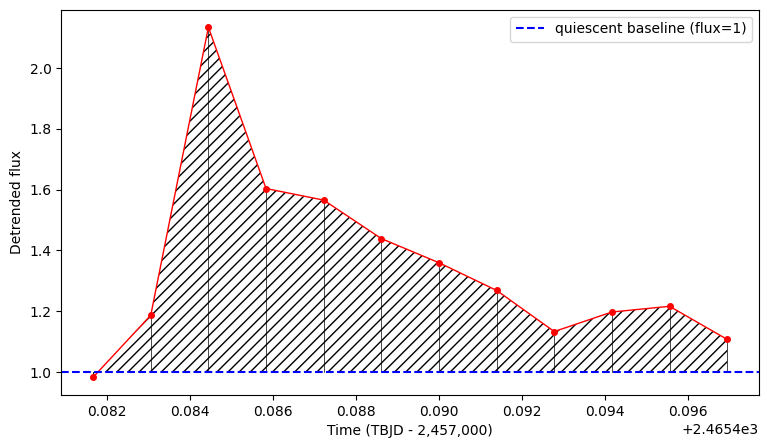

ED from the DataFrame: 497.72 seconds


In [3]:
energy_example_search = lk.search_lightcurve('TIC 114029415', mission = 'TESS', author = 'SPOC',
                                              exptime = 120, sector = 42)
energy_example_lc = energy_example_search.download()
energy_example_time = np.asarray(energy_example_lc.time.value, dtype = float)
energy_example_flux = np.asarray(energy_example_lc.flux.value, dtype = float)
energy_example_flux_err = np.asarray(energy_example_lc.flux_err.value, dtype = float)
finite = (np.isfinite(energy_example_time) & np.isfinite(energy_example_flux)
         & np.isfinite(energy_example_flux_err))
energy_example_time = energy_example_time[finite]
energy_example_flux = energy_example_flux[finite]
energy_example_flux_err = energy_example_flux_err[finite]

energy_example_orbit_time, _, energy_example_lc_wotan, _ = toffee.flatten(
    energy_example_time, energy_example_flux, energy_example_flux_err, short_window = 0.25)
energy_example_flat_flux = energy_example_lc_wotan[0]
energy_example_flat_flux_err = energy_example_lc_wotan[1]
energy_example_quality = np.zeros(len(energy_example_orbit_time))
energy_example_flares = toffee.detect_flares(energy_example_orbit_time, energy_example_flat_flux,
                                             energy_example_flat_flux_err, energy_example_quality)

#an isolated primary with no nearby secondary and a plain fast-rise/exponential-decay shape
small_flare = energy_example_flares.iloc[3]
peak_index = np.where(energy_example_orbit_time == small_flare['T_peak'])[0][0]
start_index = np.where(energy_example_orbit_time == small_flare['T_start'])[0][0]
end_index = np.where(energy_example_orbit_time == small_flare['T_end'])[0][0]

flare_time = energy_example_orbit_time[start_index:end_index + 1]
flare_flux = energy_example_flat_flux[start_index:end_index + 1]

fig, ax = plt.subplots(figsize = (9, 5))
#the hatched area IS the trapezoidal-rule integral: fill_between connects consecutive
#points with straight lines, exactly the trapezoids being summed
ax.fill_between(flare_time, flare_flux, 1.0, hatch = '///', facecolor = 'none',
                edgecolor = 'black', linewidth = 0)
#a vertical line at each cadence divides that area into the individual trapezoids
for t, f in zip(flare_time, flare_flux):
    ax.plot([t, t], [1.0, f], color = 'black', linewidth = 0.5)
ax.plot(flare_time, flare_flux, 'o-', color = 'red', markersize = 4, linewidth = 1)
ax.axhline(1.0, color = 'blue', linestyle = '--', label = 'quiescent baseline (flux=1)')
ax.set_xlabel('Time (TBJD - 2,457,000)')
ax.set_ylabel('Detrended flux')
ax.legend()
plt.show()

print(f"ED from the DataFrame: {small_flare['ED']:.2f} seconds")

## 3. ED straight from `detect_flares()`

The `ED` column is already exactly this integral, computed with `np.trapezoid` over `T_start`-`T_end` and converted from days to seconds. Reproducing it by hand confirms there's no hidden step:

In [4]:
manual_ed = np.trapezoid(flare_flux - 1, x = flare_time) * 86400  # days -> seconds
print(f"DataFrame ED:    {small_flare['ED']:.4f} s")
print(f"np.trapezoid ED: {manual_ed:.4f} s")

DataFrame ED:    497.7163 s
np.trapezoid ED: 497.7163 s


## 4. ED from a fitted model

Sometimes you want ED from the smooth rise/decay *model* instead of the raw data: less sensitive to individual noisy points, and it separates out contamination like an overlapping secondary. `big_flare` (from notebooks 1 and 3) is a good example: it has a real secondary landing in its decay, and the DataFrame's `ED` for the primary already has that secondary's contribution subtracted out.

Fit the rise and decay exactly as in notebook 3, then integrate the *fitted curves*, not the data, on a fine time grid:

In [5]:
big_flare = flares.loc[flares['Amplitude'].idxmax()]
peak_index = np.where(orbit_time == big_flare['T_peak'])[0][0]
start_index = np.where(orbit_time == big_flare['T_start'])[0][0]
end_index = np.where(orbit_time == big_flare['T_end'])[0][0]

rise_time = orbit_time[start_index:peak_index + 1]
rise_flux = flat_flux[start_index:peak_index + 1]
rise_flux_err = flat_flux_err[start_index:peak_index + 1]
decay_time = orbit_time[peak_index:end_index + 1]
decay_flux = flat_flux[peak_index:end_index + 1]
decay_flux_err = flat_flux_err[peak_index:end_index + 1]

rise_params, _, _ = toffee.fit_gaussian_rise(rise_time, rise_flux, rise_flux_err, big_flare['T_peak'])
decay_params, _, _ = toffee.fit_dbl_exp_decay(decay_time, decay_flux, decay_flux_err, big_flare['T_peak'])

#the same functional forms fit_gaussian_rise/fit_dbl_exp_decay use internally
def gaussian_rise(x, alpha, sigma, c, peak_time):
    return alpha * np.exp(-(x - peak_time)**2 / (2 * sigma)**2) + c

def dbl_exp_decay(x, alpha_0, beta_0, alpha_1, beta_1, c, peak_time):
    return alpha_0 * np.exp(-beta_0 * (x - peak_time)) + alpha_1 * np.exp(-beta_1 * (x - peak_time)) + c

#integrate the smooth model on a fine grid, not the sparse data points
fine_rise_time = np.linspace(rise_time[0], rise_time[-1], 2000)
fine_decay_time = np.linspace(decay_time[0], decay_time[-1], 2000)
model_rise_flux = gaussian_rise(fine_rise_time, *rise_params, big_flare['T_peak'])
model_decay_flux = dbl_exp_decay(fine_decay_time, *decay_params, big_flare['T_peak'])

model_ed = (np.trapezoid(model_rise_flux - 1, x = fine_rise_time) +
           np.trapezoid(model_decay_flux - 1, x = fine_decay_time)) * 86400

#for comparison: the RAW trapezoidal ED over the whole window, before subtracting the
#secondary's contribution -- this is what the primary's ED would be without that correction
raw_ed = np.trapezoid(flat_flux[start_index:end_index + 1] - 1,
                      x = orbit_time[start_index:end_index + 1]) * 86400

print(f"model-based ED (rise + decay fit):      {model_ed:.1f} s")
print(f"DataFrame ED (secondary already removed): {big_flare['ED']:.1f} s")
print(f"raw trapezoidal ED (secondary included):  {raw_ed:.1f} s")

model-based ED (rise + decay fit):      5499.9 s
DataFrame ED (secondary already removed): 5359.7 s
raw trapezoidal ED (secondary included):  5446.5 s


The model-based estimate lands within a couple percent of the data-based ones, a reasonable independent cross-check, not an exact match, since the fitted curves smooth over real structure the raw trapezoidal integral picks up directly. The gap between the raw and DataFrame numbers (~87 s) is almost exactly the secondary's own `ED`, confirming `detect_flares()` really does subtract it out of the primary.

## 5. `flare_energy_calc()`: from ED to energy

```python
def flare_energy_calc(star_luminosity, equivalent_duration):
```

| Argument | Type | Meaning |
|---|---|---|
| `star_luminosity` | float | The star's **quiescent** luminosity |
| `equivalent_duration` | float or array | ED in **seconds**, from either section 3 or 4 |

Returns `equivalent_duration * star_luminosity`: that's the whole function, following Howard & MacGregor (2022). The only thing to get right is **units**: give it a luminosity in watts and you get an energy in joules; give it a luminosity in erg/s (the usual unit in the flare literature) and you get an energy in erg.

A real stellar luminosity for this target, from the TESS Input Catalog:

In [6]:
from astroquery.mast import Catalogs

tic_row = Catalogs.query_object(f'TIC {TIC_ID}', catalog = 'TIC', radius = 0.01)[0]
luminosity_solar = tic_row['lum']

#convert solar luminosities to erg/s, the unit flare energies are usually quoted in
solar_luminosity_erg_s = 3.828e33
star_luminosity = luminosity_solar * solar_luminosity_erg_s

print(f'TIC {TIC_ID}: {luminosity_solar:.4f} solar luminosities = {star_luminosity:.3e} erg/s')

TIC 84336253: 0.0106 solar luminosities = 4.039e+31 erg/s


In [7]:
flares['Energy_erg'] = toffee.flare_energy_calc(star_luminosity, flares['ED'])
flares[['T_peak', 'Primary_or_Secondary', 'ED', 'Energy_erg']]

,T_peak,Primary_or_Secondary,ED,Energy_erg
0,2475.422539,primary,333.924647,1.348753e+34
1,2493.110102,primary,5359.732806,2.164847e+35
2,2493.115658,secondary,86.751489,3.503975e+33


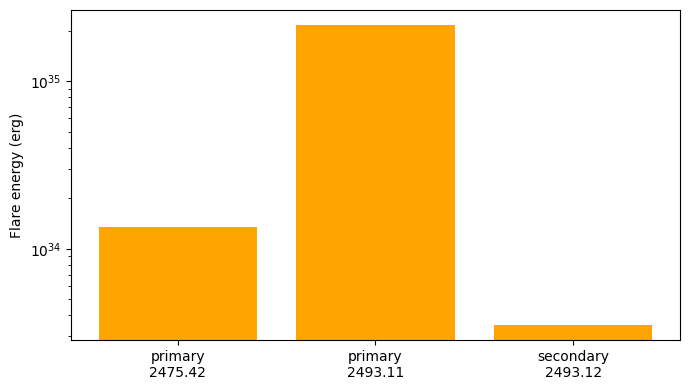

In [8]:
fig, ax = plt.subplots(figsize = (7, 4))
labels = [f"{row['Primary_or_Secondary']}\n{row['T_peak']:.2f}" for _, row in flares.iterrows()]
ax.bar(labels, flares['Energy_erg'], color = 'orange')
ax.set_yscale('log')
ax.set_ylabel('Flare energy (erg)')
plt.tight_layout()
plt.show()

## Summary

- Equivalent duration is an area (`flux - 1` integrated over time), which is why it comes out in units of time: physically, how long the star would need to shine at its quiescent brightness to match the flare's energy.
- `detect_flares()`'s `ED` column already computes this with the trapezoidal rule, and already subtracts an overlapping secondary's contribution out of its primary.
- Integrating a fitted rise/decay model instead of the raw data gives an independent cross-check, typically within a few percent.
- `flare_energy_calc(star_luminosity, equivalent_duration)` is one multiplication: the only thing to be careful about is matching `star_luminosity`'s units (W or erg/s) to the units you want the energy back in.